# Phase 4: Baseline models (FD001)

**Goal:** find out how well simple models predict remaining life on NASA's official test engines. Every later model (Phase 5 deep learning) has to beat these numbers, by more than chance, to earn its place.

Training and scoring happen in `models/baselines.py`; this notebook reads its saved results. `python -m models.verify_baselines` rechecks every number independently, and `python -m models.report_phase4` writes `docs/MODEL_METRICS.md` straight from the results so the document cannot drift.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")

res = json.loads((ROOT / "models/results_phase4.json").read_text())
preds = pd.read_csv(ROOT / "models/predictions_phase4.csv")
imp = pd.read_csv(ROOT / "models/importance_phase4.csv")
print(res["protocol"])

settings chosen on 20 validation engines; refit on all 100 training engines; test set scored once at each engine's last observed cycle; true RUL capped at 125


## 4.1 The protocol: why the test set is touched only once

**Concept:** settings (Ridge's penalty, XGBoost's tree depth and number of trees) are chosen on the **20 validation engines**. Each model is then refit on **all 100 training engines** and scored **once** on the **100 test engines**, at each engine's last observed cycle.

**Why:** if you keep adjusting a model until the test score looks good, the test score stops being an honest estimate. Using it once keeps it honest.

## 4.2 The two metrics

- **RMSE**: the typical prediction error, in cycles.
- **PHM08 score** (NASA's): with d = predicted - true, a *late* prediction (d > 0, the engine fails sooner than predicted) costs e^(d/10) - 1, while an *early* one costs e^(-d/13) - 1. Late errors are punished more because they mean an in-service failure.

True RUL is capped at 125 for scoring, the same cap used in training. The results file also reports scores against NASA's uncapped values.

In [2]:
rows = []
for name, r in res["models"].items():
    rows.append({"model": name, "validation RMSE": r["val_rmse"], "test-like validation RMSE": r["val_rmse_testlike"],
                 "test RMSE": r["rmse"],
                 "95% interval": f"{r['rmse_ci95'][0]:.1f}-{r['rmse_ci95'][1]:.1f}", "MAE": r["mae"],
                 "PHM08": r["phm"], "late predictions": f"{r['late_share']:.0%}",
                 "seed spread (sd)": r.get("seed_test_rmse_std", np.nan)})
table = pd.DataFrame(rows).round(2)
table

,model,validation RMSE,test-like validation RMSE,test RMSE,95% interval,MAE,PHM08,late predictions,seed spread (sd)
0,Fleet average,41.72,43.36,41.94,37.4-46.3,34.83,33354.47,50%,NaN
1,Age only (cycle count),26.76,31.30,31.20,27.3-35.0,25.14,3514.23,56%,NaN
2,"Ridge, raw sensors (14)",19.90,19.89,20.59,17.8-23.3,16.37,1223.93,58%,NaN
3,"Ridge, all 168 features",16.27,16.76,16.28,14.0-18.4,12.96,464.68,51%,NaN
4,"XGBoost, all 168 features",13.18,14.49,15.08,12.2-17.9,10.82,564.97,55%,0.17
5,"XGBoost, no FFT (154)",13.67,15.26,15.93,12.9-19.1,11.47,576.46,60%,0.23
6,"XGBoost, rolling only, no EMA/FFT (140)",13.60,15.17,15.98,12.9-19.1,11.46,611.34,55%,0.31
7,"XGBoost, without s9 and s14 (144)",13.82,15.21,15.96,12.7-19.1,11.34,788.53,56%,0.25
8,"XGBoost, raw sensors only (14)",16.88,18.51,17.12,13.6-20.3,11.83,1059.38,55%,0.12


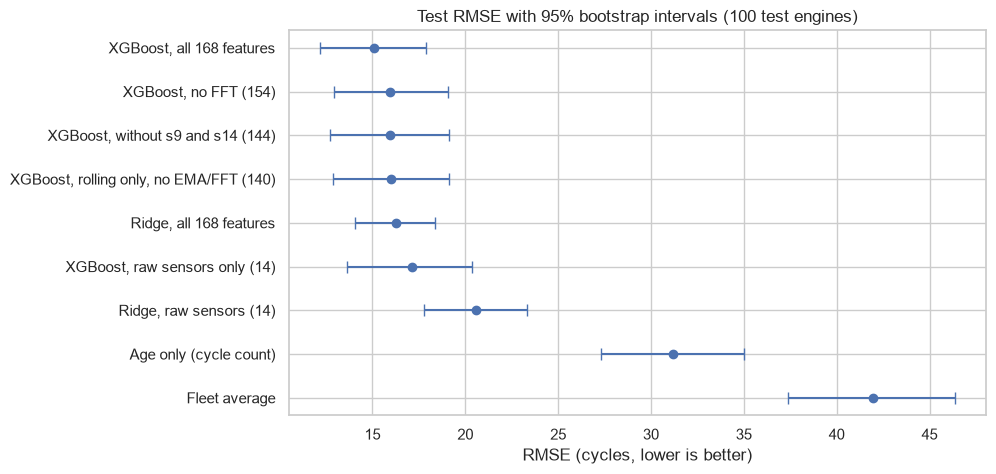

In [3]:
t = pd.DataFrame([{"model": n, "rmse": r["rmse"], "lo": r["rmse_ci95"][0], "hi": r["rmse_ci95"][1]}
                  for n, r in res["models"].items()]).sort_values("rmse")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(t.rmse, t.model, xerr=[t.rmse - t.lo, t.hi - t.rmse], fmt="o", color="#4C72B0", capsize=4)
ax.invert_yaxis()
ax.set(title="Test RMSE with 95% bootstrap intervals (100 test engines)", xlabel="RMSE (cycles, lower is better)")
fig.savefig(FIG / "fd001_baselines_rmse.png", dpi=150, bbox_inches="tight")

**Two baselines with no sensors at all:** the *fleet average* predicts one number for every engine; *age only* predicts from the cycle count alone (the average remaining life of training engines at that same cycle). A sensor model has to beat both to show it reads wear, not just age.

**Test-like validation:** the plain validation score uses every cycle of the 20 validation engines, and 39% of those sit at the easy 125 cap. The *test-like* score keeps only readings that look like the test set (at least 31 cycles observed, true RUL at most 145), so it is closer to what the test measures.

## 4.3 Choosing the published model on validation only

**Concept:** the model that goes forward must be chosen **before** looking at the test set. Here the choice is made on the 20 validation engines, comparing models where it matters (near failure) and on test-like readings.

**Why:** if the test set decides which model is published, its score is no longer an honest estimate. Because each validation engine contributes many readings, the bootstrap resamples **whole engines**, not rows (rows from the same engine are not independent).

In [4]:
sel = []
for name, c in res["model_selection_on_validation"].items():
    for key, label in (("val_near_failure_mae", "MAE, readings with <= 50 cycles left"), ("val_testlike_rmse", "RMSE, test-like readings")):
        lo, hi = c[key]["ci"]
        sel.append({"comparison on validation": name, "measure": label, "gap A - B": round(c[key]["diff"], 2),
                    "95% interval": f"{lo:+.2f} to {hi:+.2f}", "verdict": "A better" if hi < 0 else "no clear difference"})
pd.DataFrame(sel)

,comparison on validation,measure,gap A - B,95% interval,verdict
0,"XGBoost, all 168 features vs Ridge, all 168 fe...","MAE, readings with <= 50 cycles left",-6.65,-8.35 to -5.05,A better
1,"XGBoost, all 168 features vs Ridge, all 168 fe...","RMSE, test-like readings",-2.27,-4.09 to -0.80,A better
2,"XGBoost, all 168 features vs Age only (cycle c...","MAE, readings with <= 50 cycles left",-25.40,-30.22 to -20.70,A better
3,"XGBoost, all 168 features vs Age only (cycle c...","RMSE, test-like readings",-16.81,-21.49 to -12.25,A better


## 4.4 Is a gap on the test set real, or luck?

**Concept:** a *paired bootstrap* resamples the same 100 test engines thousands of times and recomputes the gap between two models each time. If the 95% interval of the gap excludes 0, the difference is real; if it includes 0, the test set cannot tell the two models apart.

**Why:** with only 100 test engines, a 1-cycle difference in RMSE can easily be luck. Claiming one model is better without this check is the most common overclaim in student ML projects.

**Holm correction:** nine comparisons are tested at once, so one could look significant by chance. Holm's method raises the bar for each comparison in turn; a gap counts as real only if its Holm-adjusted p-value is below 0.05.

In [5]:
comp = []
for name, c in res["paired_comparisons"].items():
    for metric in ("rmse", "phm"):
        lo, hi = c[metric]["ci"]
        comp.append({"comparison (A vs B)": name, "metric": metric.upper(), "gap A - B": round(c[metric]["diff"], 2),
                     "95% interval": f"{lo:+.2f} to {hi:+.2f}", "Holm p": round(c[metric]["p_holm"], 3),
                     "verdict": ("A better" if c[metric]["diff"] < 0 else "B better") if c[metric]["significant"] else "no clear difference"})
pd.DataFrame(comp)

,comparison (A vs B),metric,gap A - B,95% interval,Holm p,verdict
0,"XGBoost, all 168 features vs Fleet average",RMSE,-26.86,-33.18 to -20.92,0.005,A better
1,"XGBoost, all 168 features vs Fleet average",PHM,-32789.50,-47024.20 to -20056.33,0.005,A better
2,"XGBoost, all 168 features vs Age only (cycle c...",RMSE,-16.12,-20.84 to -11.35,0.005,A better
3,"XGBoost, all 168 features vs Age only (cycle c...",PHM,-2949.26,-4764.10 to -1426.78,0.005,A better
4,"XGBoost, all 168 features vs Ridge, raw sensor...",RMSE,-5.51,-8.89 to -2.16,0.005,A better
5,"XGBoost, all 168 features vs Ridge, raw sensor...",PHM,-658.96,-1730.76 to +94.11,0.525,no clear difference
6,"XGBoost, all 168 features vs Ridge, all 168 fe...",RMSE,-1.20,-3.05 to +0.75,0.610,no clear difference
7,"XGBoost, all 168 features vs Ridge, all 168 fe...",PHM,100.29,-121.50 to +425.65,1.000,no clear difference
8,"XGBoost, all 168 features vs XGBoost, no FFT (...",RMSE,-0.85,-2.17 to +0.26,0.610,no clear difference
9,"XGBoost, all 168 features vs XGBoost, no FFT (...",PHM,-11.49,-219.84 to +193.77,1.000,no clear difference


## 4.5 Where the errors are

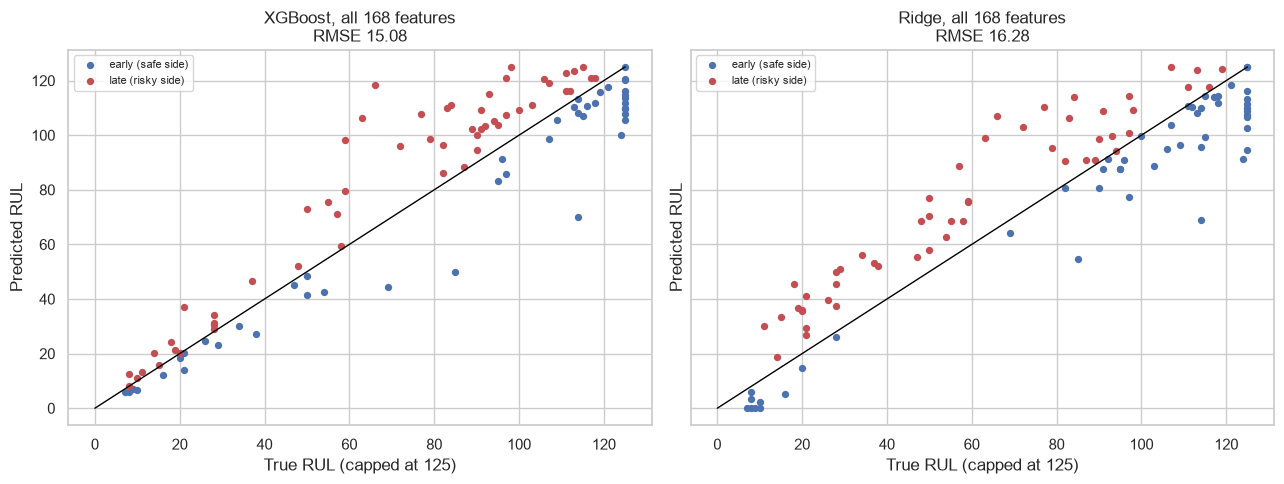

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axes, ["XGBoost, all 168 features", "Ridge, all 168 features"]):
    late = preds[m] > preds.RUL
    ax.scatter(preds.RUL[~late], preds[m][~late], s=18, label="early (safe side)", color="#4C72B0")
    ax.scatter(preds.RUL[late], preds[m][late], s=18, label="late (risky side)", color="#C44E52")
    ax.plot([0, 125], [0, 125], color="black", linewidth=1)
    ax.set(title=f"{m}\nRMSE {res['models'][m]['rmse']:.2f}", xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fd001_baselines_pred_vs_true.png", dpi=150, bbox_inches="tight")

In [7]:
m = "XGBoost, all 168 features"
err = (preds[m] - preds.RUL).abs()
bands = pd.cut(preds.RUL, [0, 25, 50, 75, 100, 125], include_lowest=True)
pd.DataFrame({"engines": err.groupby(bands, observed=False).size(),
              "mean absolute error": err.groupby(bands, observed=False).mean().round(1)})

,engines,mean absolute error
RUL,,
"(-0.001, 25.0]",19,3.2
"(25.0, 50.0]",14,6.0
"(50.0, 75.0]",10,25.1
"(75.0, 100.0]",24,15.3
"(100.0, 125.0]",33,9.7


### Near failure, where maintenance decisions are made

Overall scores mix healthy and worn engines. Validation already showed XGBoost is clearly better near failure (section 4.3); this checks that the test set agrees, on the 33 test engines with 50 or fewer cycles left.

In [8]:
from models.metrics import mae, paired_bootstrap
near = preds.RUL <= 50
rows = []
for m in ["XGBoost, all 168 features", "Ridge, all 168 features"]:
    d = preds[m][near] - preds.RUL[near]
    rows.append({"model": m, "engines": int(near.sum()), "MAE": round(d.abs().mean(), 1),
                 "mean signed error (+ = late)": round(d.mean(), 1), "late share": f"{(d > 0).mean():.0%}"})
display(pd.DataFrame(rows))
c = paired_bootstrap(preds.RUL[near], preds["XGBoost, all 168 features"][near], preds["Ridge, all 168 features"][near], metric=mae)
print(f"MAE gap XGBoost - Ridge: {c['diff']:+.1f} cycles, 95% interval {c['ci'][0]:+.1f} to {c['ci'][1]:+.1f}, XGBoost better in {c['a_wins']:.0%} of resamples")

,model,engines,MAE,mean signed error (+ = late),late share
0,"XGBoost, all 168 features",33,4.4,1.0,52%
1,"Ridge, all 168 features",33,13.3,9.3,70%


MAE gap XGBoost - Ridge: -9.0 cycles, 95% interval -11.4 to -6.8, XGBoost better in 100% of resamples


['s4_ema', 's4_mean10', 's15_mean10', 's11_mean10', 's4_mean5', 's15_ema', 's15_mean5', 's3_ema', 's2_mean10', 's9_mean5', 's11_mean5', 's2_ema', 's9_mean10', 's9_ema', 's21_ema']


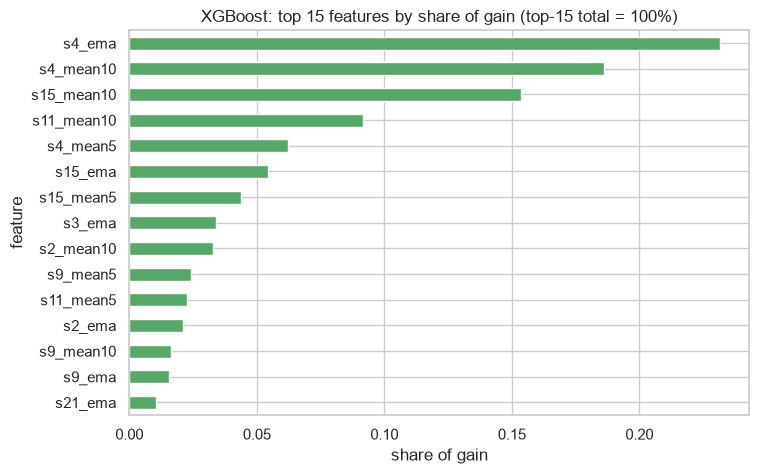

In [9]:
top = imp.head(15).set_index("feature")["gain"]
fig, ax = plt.subplots(figsize=(8, 5))
(top / top.sum())[::-1].plot.barh(ax=ax, color="#55A868")
ax.set(title="XGBoost: top 15 features by share of gain (top-15 total = 100%)", xlabel="share of gain")
fig.savefig(FIG / "fd001_xgb_importance.png", dpi=150, bbox_inches="tight")
print(top.index.tolist())

## What the results say

1. **Feature engineering is the big win, and it is real.** The same linear model goes from 20.59 to 16.28 RMSE when given the Phase 3 features (gap -4.31, Holm-adjusted p 0.005).
2. **Sensors carry far more than age.** Age alone scores 31.20 RMSE, better than the fleet average (41.94) but 2.1 times XGBoost's error.
3. **Over all 100 test engines, XGBoost and Ridge on the same features are statistically tied** (RMSE gap -1.20, interval -3.05 to +0.75; Ridge has the better PHM08, also not significant).
4. **XGBoost was chosen on validation, and the test set agrees.** On the 20 validation engines it beats Ridge near failure (MAE gap -6.65, interval -8.35 to -5.05, whole engines resampled) and on test-like readings (-2.27). On test, near failure, its MAE is 4.4 cycles against Ridge's 13.3 (gap -9.0, interval -11.4 to -6.8), and Ridge runs late by +9.3 cycles on average. The test result holds at every cut-off from 25 to 75 cycles left.
5. **FFT, EMA and s9/s14 have no measurable effect.** Removing any of them raises test RMSE by about 0.9 cycles, but no gap is significant after Holm correction (smallest Holm p 0.54). All three gaps point the same way (the full set is slightly better), so these features may help a little, but 100 test engines cannot show it. They are kept, and this is stated.
6. **Holm correction removed one claim.** Without it this looked significant; tested together with the other comparisons it is not: XGBoost, all 168 features vs XGBoost, raw sensors only (14) on PHM (Holm p 0.24).
7. **Validation, test-like validation and test agree in order.** XGBoost scores 13.18 on all validation rows, 14.49 on test-like rows and 15.08 on test: the test-like view explains most of the gap.
8. **Most accurate where it matters most:** XGBoost's MAE is 3.2 cycles for engines within 25 cycles of failure and 6.0 for 26-50; the largest errors (25.1) are at 50-75 cycles left.
9. **Reproducible on any machine.** XGBoost runs on one fixed thread (thread count alone moved predictions by up to 10 cycles). Its random row/column sampling still differs between operating systems, so the verifier demands identical predictions on the OS that produced them (Windows) and, elsewhere (CI runs Linux), that 5 re-run seeds match the published 5-seed mean within 0.6 RMSE.
10. **The bar for Phase 5:** beat **15.08 RMSE and 565 PHM08** with a paired, Holm-corrected test that excludes 0, and stay at least as accurate near failure.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Fixed the protocol: tune on validation, refit on all training engines, test once | Re-using the test set to tune makes its score dishonest | Every setting is the minimum of a validation search, checked independently | Phase 5 follows the same protocol |
| 2 | Chose the published model on validation, resampling whole engines | Picking the winner from test results would leak the test set into the choice | XGBoost wins near failure on validation (-6.6 MAE); test confirms (-9.0) | Phase 5 must also be chosen on validation |
| 3 | Used RMSE and the PHM08 score | RMSE treats early and late errors alike; maintenance does not | Rankings can differ by metric | Every later model is reported on both |
| 4 | Fleet-average and age-only baselines | Show what you get with no sensors, and with age only | 41.9 and 31.2 RMSE: sensors add a lot beyond age | Confirms the models read wear, not just time |
| 5 | Ridge on raw sensors vs on 168 features | Separates the value of features from model power | Features alone cut RMSE by 4.3 cycles, a real gap | Phase 3 is justified with evidence |
| 6 | XGBoost with 5 seeds, depth search on two validation views | Shows chance variation; checks the depth choice is robust | Seed spread sd 0.17; depth 5 chosen | Phase 5 reports seed spread too |
| 7 | Ablations: no FFT, no EMA, no s9/s14, raw only | Phase 3 left open whether these features help | None changes accuracy measurably | Feature set stays; stated honestly |
| 8 | Paired bootstrap with Holm correction | 100 engines is small and 9 comparisons are tested at once | Only gaps that survive the correction are claimed | All later claims use the same correction |
| 9 | Pinned the NASA files by checksum and the library versions; CI downloads the data and runs every verifier | Results must reproduce on a clean machine, on byte-identical data | Verification no longer depends on my laptop | Every push re-proves the published numbers |
| 10 | Fixed XGBoost to one thread; OS-aware reproduction check | CI on Linux could not reproduce predictions made on Windows (off by 6.8 cycles) | Thread count and the OS's random functions both change tree models | Phase 5 fixes threads and seeds, and records the environment |
| 11 | Independent verification and generated documents (metrics doc, these findings, README check) | Resume numbers must be exactly reproducible and match the docs | Caught a float32 mismatch, a shadowed variable, a Holm tie bug and stale prose | Every phase keeps a verifier and generated docs |

**The habit to keep:** a model is "better" only if the gap survives a fair test on the same engines. Otherwise, report a tie.